In [ ]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
set_font_size(18)

## Procedure
1. run ./ros2_run.sh   python3 GUI_MultiVMC_Torque.py    python3 GUI_MultiVMC.py
2. Modify the configuration file to use 3 linear springs
In the GUI follow do this:
3. set spring1 to k = 100 and all the others to k = 0
4. move spring1 to x = 0.4 and z = 0.21 (this corresponds to configuration 1)
5. move spring2,3 to x = 0.4 and z = 0.21
6. set k = 200 for spring2,3 (this corresponds to configuration 2)
7. (in the gaussian case we would also move the gaussian to x = -0.1 and set k = 400)

# Three Springs vs One — Before/After Activation (x-z plane)

Experiment (using **filtered.npz**, all samples with t ≥ 400 s):

- **3 linear springs** along the robot body. The tip spring `lin_seg3` (s=1.0) is held
  at **k=100** the whole time.
- The two body springs `lin_seg2` (s=0.667) and `lin_seg_middle` (s=0.5) start at
  **k=0** and are switched to **k=200** at a single transition.
- Motion is purely along **x** (y ≈ 0), so we visualise the robot in the **x-z plane**.

We compare the robot's posture **5 s before** the k=0→200 transition (blue) against the
settled posture **5 s after** (red), on the same axes. No intermediate trajectory is shown.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

d = np.load("outputs/three_spring_vs_one/filtered.npz", allow_pickle=True)
t       = d["t"]
k       = d["k_params"]          # (n, 3) stiffness per component
cp      = d["comp_pos"]          # (n, 3, 3) measured pos per component (x,y,z)
names   = [str(s) for s in d["comp_names"]]
s_param = d["comp_s_params"]

# ── Find the k=0 -> 200 transition of the two body springs (component 1) ──
kc = k[:, 1]
trans_idx = np.where((kc[:-1] < 100) & (kc[1:] >= 100))[0][0] + 1
t_trans = t[trans_idx]
print(f"Components: {names}  (s={list(np.round(s_param,3))})")
print(f"Transition k=0->200 at t = {t_trans:.2f} s")
print(f"Tip spring '{names[0]}' k unique: {np.unique(k[:,0])}")
print(f"Body springs k unique: {np.unique(k[:,1])}, {np.unique(k[:,2])}")


Components: ['lin_seg3', 'lin_seg2', 'lin_seg_middle']  (s=[np.float64(1.0), np.float64(0.667), np.float64(0.5)])
Transition k=0->200 at t = 415.46 s
Tip spring 'lin_seg3' k unique: [100.]
Body springs k unique: [  0. 200.], [  0. 200.]


## Before / after postures

For each phase we average the measured positions over a settled window:
- **Before** — the 5 s leading up to the transition (already at rest).
- **After**  — the tail of the 5 s following the transition (settled at the new posture).

The robot backbone is drawn base → `lin_seg_middle` → `lin_seg2` → `lin_seg3` (tip),
ordered by s-parameter.

In [2]:
HALF = 5.0   # seconds before/after the transition to consider

def mean_pose(t_lo, t_hi):
    """Mean (x,z) of each component over [t_lo, t_hi); returns backbone incl. base."""
    m = (t >= t_lo) & (t < t_hi)
    pts = cp[m].mean(axis=0)            # (3, 3) -> mean x,y,z per component
    order = np.argsort(s_param)         # base..tip by s
    xz = np.column_stack([pts[order, 0], pts[order, 2]])   # (3, 2) -> (x, z)
    base = np.array([[0.0, 0.0]])       # robot root at origin
    return np.vstack([base, xz])        # (4, 2)

# Before: full 5 s pre-transition (settled).  After: last 1.5 s of the 5 s window (settled).
before = mean_pose(t_trans - HALF, t_trans)
after  = mean_pose(t_trans + HALF - 1.5, t_trans + HALF)

print("Backbone (x, z)  [base, middle, seg2, tip]")
print("BEFORE:\n", np.round(before, 4))
print("AFTER :\n", np.round(after, 4))


Backbone (x, z)  [base, middle, seg2, tip]
BEFORE:
 [[0.     0.    ]
 [0.0654 0.1694]
 [0.1441 0.2461]
 [0.2698 0.3195]]
AFTER :
 [[0.     0.    ]
 [0.1103 0.1469]
 [0.2142 0.1901]
 [0.354  0.2265]]


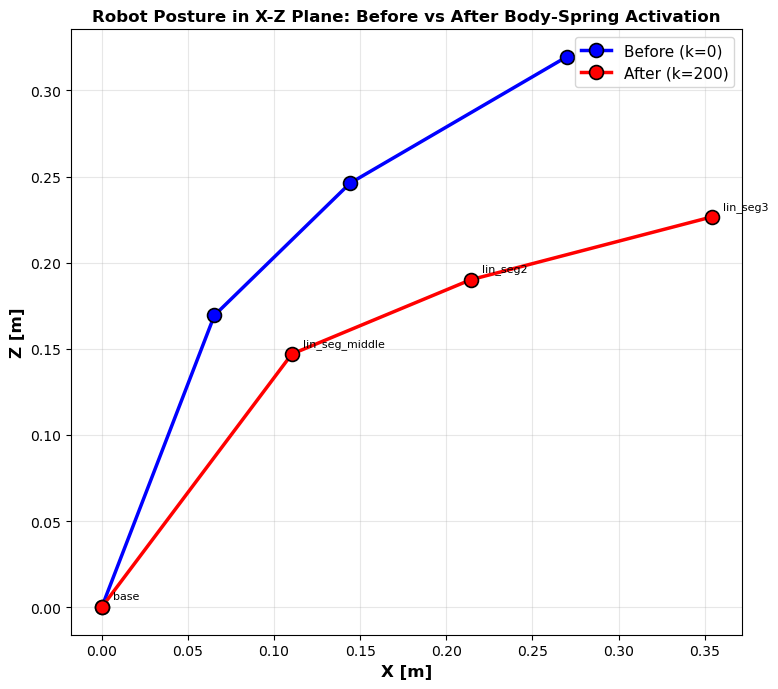

Saved filtered.png


In [3]:
fig, ax = plt.subplots(figsize=(8, 7))

labels = ["base", names[2], names[1], names[0]]   # base, middle(s=.5), seg2(.667), tip(1.0)

for pose, color, tag in [(before, "blue", "Before (k=0)"),
                         (after,  "red",  "After (k=200)")]:
    ax.plot(pose[:, 0], pose[:, 1], "-o", color=color, linewidth=2.5,
            markersize=10, markeredgecolor="black", markeredgewidth=1.2,
            label=tag, zorder=3)

# Annotate the joints on the AFTER posture
for (x, z), lab in zip(after, labels):
    ax.annotate(lab, (x, z), textcoords="offset points", xytext=(8, 6), fontsize=8)

ax.set_xlabel("X [m]", fontsize=12, fontweight="bold")
ax.set_ylabel("Z [m]", fontsize=12, fontweight="bold")
ax.set_title("Robot Posture in X-Z Plane: Before vs After Body-Spring Activation",
             fontsize=12, fontweight="bold")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11, loc="best")
plt.tight_layout()
plt.savefig(os.path.join("outputs", "three_spring_vs_one", "filtered.pdf"))
plt.show()
print("Saved filtered.png")
